# Chapitre 5 - Cours 2 : prompt système, gabarits de conversation et longueur de contexte

Au cours 1, nous avons manipulé des prompts comme du texte. Mais le modèle ne voit jamais
« un prompt système » et « un prompt utilisateur » : il voit **une seule séquence de tokens**,
fabriquée par un **gabarit de conversation** (*chat template*). Ce cours ouvre le capot.

Sections du livre couvertes : *System Prompt and User Prompt* et *Context Length and Context
Efficiency*. Plan :

1. prompt système et prompt utilisateur : deux rôles, une seule séquence ;
2. le gabarit réel de Qwen (ChatML) et ses tokens spéciaux, visualisés token par token ;
3. erreurs de gabarit : une panne silencieuse, mesurée ;
4. le prompt système a-t-il plus de poids ? conflits d'instructions ;
5. longueur de contexte : course aux fenêtres, mémoire du cache KV, coût quadratique ;
6. l'aiguille dans une botte de foin : où le modèle trouve-t-il l'information ?

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoConfig

from aie import llm
from aie import ch05_prompts as P
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN,
                          LIGHT, annotate_bars, subtitle, finish)

set_style()
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 100)
tok = P._tokenizer(llm.SMALL)

## 1. Prompt système et prompt utilisateur (section *System Prompt and User Prompt*)

**Motivation.** La plupart des API séparent le prompt en deux : le **prompt système**
(souvent écrit par le développeur de l'application : rôle, règles, format) et le **prompt
utilisateur** (la demande de l'utilisateur, éventuellement accompagnée d'un document). On peut
voir le prompt système comme la *description de la tâche* et le prompt utilisateur comme la
*tâche* du cours 1.

Prenons un assistant qui aide des locataires à comprendre leur bail : le rôle (« juriste
spécialisé en baux d'habitation, réponses courtes et prudentes ») va dans le système, la
question et le bail dans le message utilisateur.

**Point clé du livre.** Sous le capot, système et utilisateur sont **concaténés** en une seule
séquence selon un gabarit, puis traités de la même façon par le transformer. Si le prompt
système « pèse » davantage, c'est (1) parce qu'il vient en premier, et/ou (2) parce que le
modèle a été **post-entraîné** à lui accorder la priorité (hiérarchie d'instructions,
Wallace et al., 2024 ; voir le cours 4).

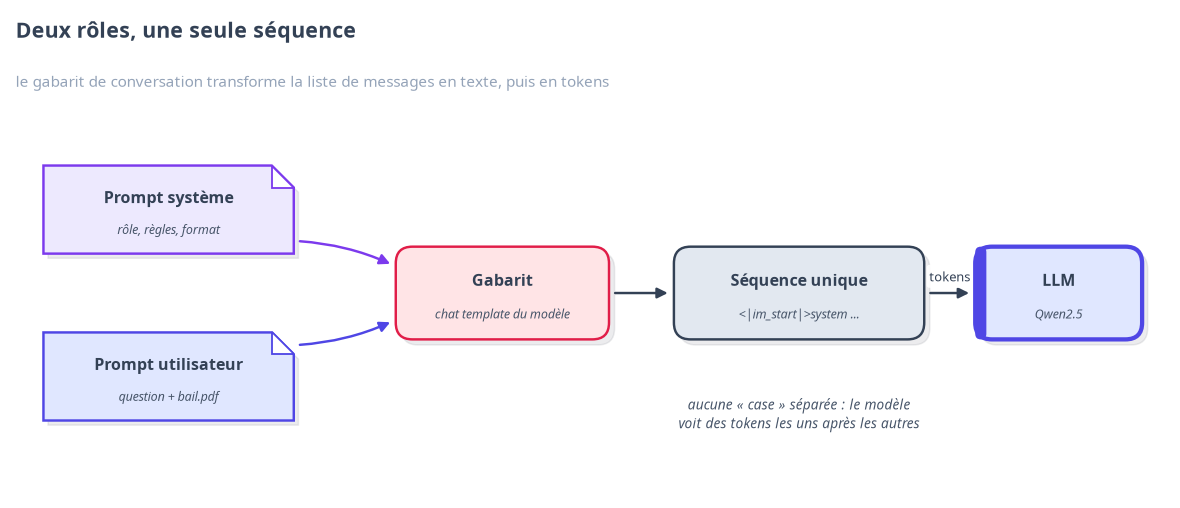

In [2]:
d = Diagram(12.5, 4.3, title="Deux rôles, une seule séquence",
            subtitle="le gabarit de conversation transforme la liste de messages en texte, puis en tokens")
d.box("sys", 1.7, 3.1, "Prompt système", sub="rôle, règles, format", color=VIOLET, kind="doc", w=2.7, h=0.95)
d.box("usr", 1.7, 1.3, "Prompt utilisateur", sub="question + bail.pdf", color=INDIGO, kind="doc", w=2.7, h=0.95)
d.box("tpl", 5.3, 2.2, "Gabarit", sub="chat template du modèle", color=ROSE, w=2.3, h=1.0)
d.box("seq", 8.5, 2.2, "Séquence unique", sub="<|im_start|>system ...", color=SLATE, w=2.7, h=1.0)
d.box("llm", 11.3, 2.2, "LLM", sub="Qwen2.5", color=INDIGO, kind="model", w=1.8, h=1.0)
d.arrow("sys", "tpl", rad=-0.1, color=VIOLET)
d.arrow("usr", "tpl", rad=0.1, color=INDIGO)
d.arrow("tpl", "seq")
d.arrow("seq", "llm", "tokens")
d.note(8.5, 0.9, "aucune « case » séparée : le modèle\nvoit des tokens les uns après les autres", fontsize=9)
d.show()

In [3]:
messages = [
    {"role": "system", "content": "Tu es un juriste spécialisé en baux d'habitation. Réponds en deux phrases, avec prudence."},
    {"role": "user", "content": "Contexte : [bail.pdf]\nQuestion : mon propriétaire peut-il augmenter le loyer en cours de bail ?"},
]
print(P.render_chat(messages))

<|im_start|>system
Tu es un juriste spécialisé en baux d'habitation. Réponds en deux phrases, avec prudence.<|im_end|>
<|im_start|>user
Contexte : [bail.pdf]
Question : mon propriétaire peut-il augmenter le loyer en cours de bail ?<|im_end|>
<|im_start|>assistant



Voilà le texte que le modèle reçoit réellement. Les balises `<|im_start|>` et `<|im_end|>`
délimitent chaque tour ; la dernière ligne `<|im_start|>assistant` est le **prompt de
génération** : elle « passe la parole » au modèle.

> **À retenir.** Système et utilisateur ne sont que deux segments d'une même séquence. Le
> gabarit de conversation est la « colle » qui les assemble.

## 2. Le gabarit réel de Qwen et ses tokens spéciaux (section *System Prompt and User Prompt*)

Qwen2.5 utilise le format **ChatML**. Le livre montre les gabarits de Llama 2 et de Llama 3 :
chaque famille (et parfois chaque version) a le sien. Comparons les trois sur la même
conversation (ceux de Llama sont réécrits à la main dans `manual_template`).

In [4]:
conv = [{"role": "system", "content": "Traduis le texte en anglais."},
        {"role": "user", "content": "Comment vas-tu ?"}]
for style in ["chatml", "llama2", "llama3"]:
    print(f"--- {style} ---")
    print(P.manual_template(conv, style))
assert P.manual_template(conv, "chatml") == P.render_chat(conv)  # notre ChatML = gabarit officiel

--- chatml ---
<|im_start|>system
Traduis le texte en anglais.<|im_end|>
<|im_start|>user
Comment vas-tu ?<|im_end|>
<|im_start|>assistant

--- llama2 ---
<s>[INST] <<SYS>>
Traduis le texte en anglais.
<</SYS>>

Comment vas-tu ? [/INST]
--- llama3 ---
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Traduis le texte en anglais.<|eot_id|><|start_header_id|>user<|end_header_id|>

Comment vas-tu ?<|eot_id|><|start_header_id|>assistant<|end_header_id|>




Visualisons maintenant le prompt **token par token**, coloré par rôle. La conversation
comporte un prompt système, un échange, puis un appel d'outil dont la réponse revient au
modèle (rôle `tool`).

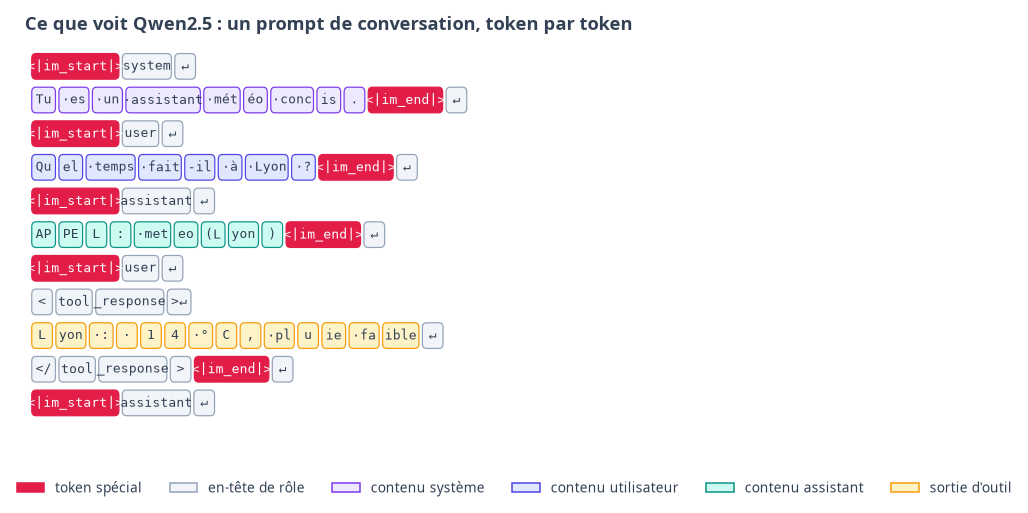

In [5]:
conv_outil = [
    {"role": "system", "content": "Tu es un assistant météo concis."},
    {"role": "user", "content": "Quel temps fait-il à Lyon ?"},
    {"role": "assistant", "content": "APPEL: meteo(Lyon)"},
    {"role": "tool", "content": "Lyon : 14 °C, pluie faible"},
]
seg = P.role_segments(conv_outil)
P.plot_token_strip(seg, width=14, title="Ce que voit Qwen2.5 : un prompt de conversation, token par token")
plt.show()

Ce que la figure révèle :

- les **tokens spéciaux** (en rose plein) sont des tokens **uniques** du vocabulaire :
  `<|im_start|>` n'est pas découpé en `<`, `|`, `im`... Ils ne peuvent pas apparaître par
  hasard dans un texte tokenisé normalement ;
- le nom du rôle et les sauts de ligne (en gris) sont du texte ordinaire ajouté par le gabarit ;
- la sortie d'outil est rendue **à l'intérieur d'un tour `user`**, entre balises
  `<tool_response>` : pour le modèle, c'est presque un message utilisateur. Nous verrons au
  cours 4 pourquoi c'est la porte d'entrée de l'injection de prompt indirecte.

Et si l'on n'écrit **pas** de prompt système ? Le gabarit de Qwen en ajoute un **par défaut**.

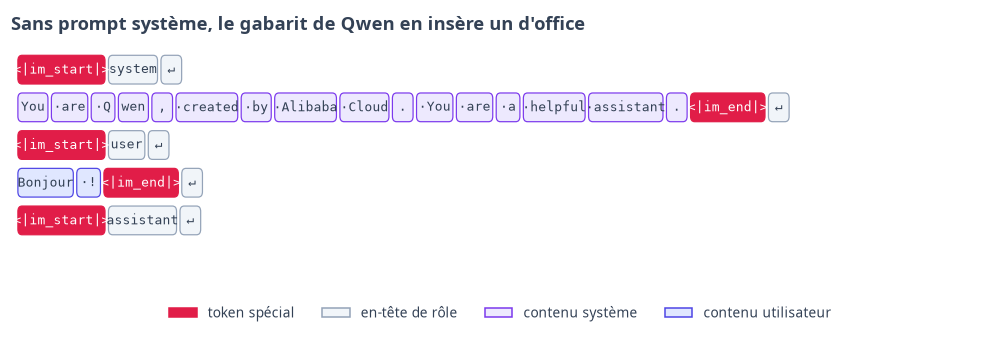

,token,identifiant,rôle
0,<|im_start|>,151644,début de tour
1,<|im_end|>,151645,fin de tour (arrêt de génération)
2,<|endoftext|>,151643,fin de document / rembourrage
3,<tool_call>,151657,début d'appel d'outil
4,</tool_call>,151658,fin d'appel d'outil


In [6]:
seg2 = P.role_segments([{"role": "user", "content": "Bonjour !"}])
P.plot_token_strip(seg2, width=14, title="Sans prompt système, le gabarit de Qwen en insère un d'office")
plt.show()

ids = {t: tok.convert_tokens_to_ids(t) for t in ["<|im_start|>", "<|im_end|>", "<|endoftext|>", "<tool_call>", "</tool_call>"]}
pd.DataFrame({"token": list(ids), "identifiant": list(ids.values()),
              "rôle": ["début de tour", "fin de tour (arrêt de génération)", "fin de document / rembourrage",
                       "début d'appel d'outil", "fin d'appel d'outil"]})

Le prompt système par défaut (« You are Qwen, created by Alibaba Cloud... ») fait partie du
comportement attendu du modèle : il a été post-entraîné avec. C'est un exemple concret de
l'avertissement du livre : **imprimez toujours le prompt final** avant d'envoyer une requête ;
une bibliothèque peut ajouter ou modifier des choses à votre insu.

**Coût du gabarit.** Combien de tokens le gabarit ajoute-t-il par message ?

In [7]:
def overhead(msgs):
    rendered = len(tok(P.render_chat(msgs), add_special_tokens=False)["input_ids"])
    contenu = sum(len(tok(m["content"], add_special_tokens=False)["input_ids"]) for m in msgs)
    return rendered - contenu

rows = []
for n_tours in [1, 2, 5, 10, 20]:
    msgs = [{"role": "system", "content": "Sois bref."}]
    for i in range(n_tours):
        msgs += [{"role": "user", "content": "Question ?"}, {"role": "assistant", "content": "Réponse."}]
    rows.append(dict(tours=n_tours, messages=len(msgs), tokens_de_gabarit=overhead(msgs)))
oh = pd.DataFrame(rows)
oh["par_message"] = (oh.tokens_de_gabarit / oh.messages).round(2)
oh

,tours,messages,tokens_de_gabarit,par_message
0,1,3,18,6.00
1,2,5,28,5.60
2,5,11,58,5.27
3,10,21,108,5.14
4,20,41,208,5.07


Environ 5 tokens par message (`<|im_start|>`, le rôle, `\n`, `<|im_end|>`, `\n`), plus le
prompt de génération. C'est négligeable pour une conversation, mais pas pour un prompt
few-shot en tours de conversation avec beaucoup d'exemples courts (cours 1) : chaque exemple
coûte deux messages, donc une dizaine de tokens de structure.

> **À retenir.** Chaque famille de modèles a son gabarit, avec des tokens spéciaux atomiques.
> Le gabarit peut insérer du contenu (prompt système par défaut) : on imprime toujours le
> prompt final.

## 3. Erreurs de gabarit : une panne silencieuse (section *System Prompt and User Prompt*)

Le livre met en garde : un mauvais gabarit (ou un simple saut de ligne en trop) peut changer
le comportement du modèle, et ces erreurs sont des **pannes silencieuses** : le modèle produit
quelque chose de raisonnable, donc personne ne remarque la dégradation. Mesurons-la sur la
tâche de classification du cours 1, avec 8 exemples en tours de conversation, en ne changeant
**que** le gabarit.

In [8]:
pool, test = P.split_intents(4, seed=0)
shots8 = P.sample_shots(pool, 8, seed=0)
y_true = [y for _, y in test]

def rendre(msgs, variante):
    if variante == "officiel (ChatML)":
        return P.render_chat(msgs)
    if variante == "sans prompt de génération":
        return P.render_chat(msgs, add_generation_prompt=False)
    if variante == "saut de ligne en trop":
        return P.render_chat(msgs).replace("<|im_end|>\n", "<|im_end|>\n\n")
    if variante == "gabarit Llama 3":
        return P.manual_template(msgs, "llama3")
    if variante == "gabarit Llama 2":
        return P.manual_template(msgs, "llama2")
    if variante == "rôles en clair, sans tokens":
        return P.manual_template(msgs, "brut") + " "
    raise ValueError(variante)

VARIANTES = ["officiel (ChatML)", "saut de ligne en trop", "sans prompt de génération",
             "gabarit Llama 3", "gabarit Llama 2", "rôles en clair, sans tokens"]
rows = []
for v in VARIANTES:
    for k, shots in [(0, []), (8, shots8)]:
        preds = [P.predict_from_prefix(rendre(P.few_shot_messages(P.INTENT_DESCRIPTION, shots, x), v))
                 for x, _ in test]
        rows.append(dict(gabarit=v, k=k, precision=np.mean([a == b for a, b in zip(preds, y_true)])))
tpl = pd.DataFrame(rows).pivot(index="gabarit", columns="k", values="precision").loc[VARIANTES]
tpl.columns = ["0 exemple", "8 exemples"]
tpl.round(3)

,0 exemple,8 exemples
gabarit,,
officiel (ChatML),0.475,0.650
saut de ligne en trop,0.450,0.650
sans prompt de génération,0.250,0.250
gabarit Llama 3,0.300,0.625
gabarit Llama 2,0.300,0.700
"rôles en clair, sans tokens",0.300,0.325


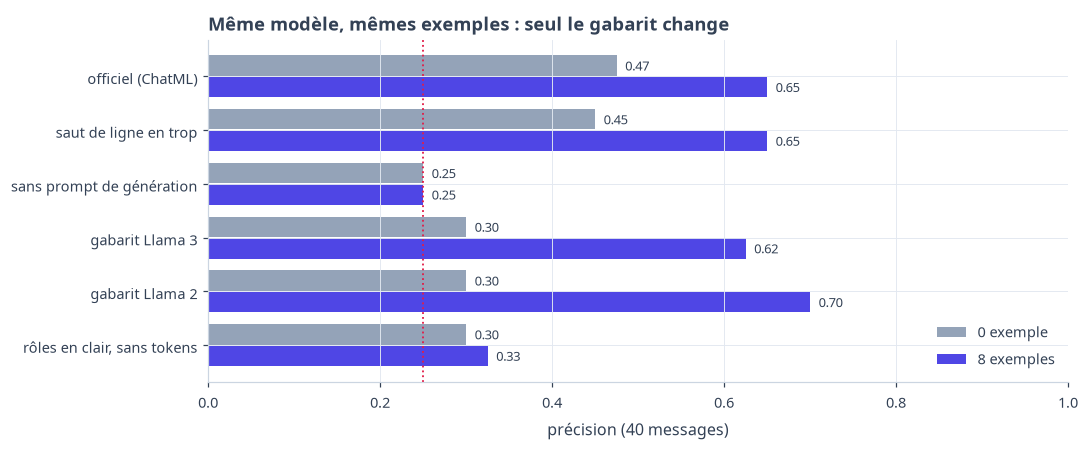

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(tpl))
ax.barh(y - 0.2, tpl["0 exemple"], height=0.38, color=GRAY, label="0 exemple")
ax.barh(y + 0.2, tpl["8 exemples"], height=0.38, color=INDIGO, label="8 exemples")
for i, (a, b) in enumerate(zip(tpl["0 exemple"], tpl["8 exemples"])):
    ax.text(a + 0.01, i - 0.2, f"{a:.2f}", va="center", fontsize=8.5)
    ax.text(b + 0.01, i + 0.2, f"{b:.2f}", va="center", fontsize=8.5)
ax.set_yticks(y, tpl.index)
ax.invert_yaxis()
ax.axvline(0.25, color=ROSE, ls=":", lw=1.2)
ax.set_xlim(0, 1)
ax.set_xlabel("précision (40 messages)")
ax.set_title("Même modèle, mêmes exemples : seul le gabarit change")
ax.legend(loc="lower right")
finish(fig)
plt.show()

**Lecture.**

- **Sans exemple**, tout écart au gabarit officiel fait chuter la précision vers le hasard
  (25 %), sauf le saut de ligne en trop, presque anodin ici.
- **Avec 8 exemples**, les exemples « sauvent » en partie les gabarits étrangers (Llama 2 et
  Llama 3) : le modèle réapprend le format en contexte, et un gabarit étranger peut même
  faire légèrement mieux que l'officiel sur cette configuration (le livre note que c'est rare
  mais possible). En revanche, oublier le **prompt de génération** ou écrire les rôles en
  clair reste catastrophique.

Rien ne signale l'erreur : seul un jeu d'évaluation la révèle. Voyons à quoi
ressemble une réponse générée avec un mauvais gabarit.

In [10]:
def generer_brut(texte, n=40):
    tk, model = llm.load(llm.SMALL)
    ids = tk(texte, return_tensors="pt", add_special_tokens=False).to(model.device)
    with torch.no_grad():
        out = model.generate(**ids, max_new_tokens=n, do_sample=False, pad_token_id=tk.pad_token_id)
    return tk.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=False)

q = [{"role": "user", "content": "Donne une capitale européenne, en un mot."}]
demo = pd.DataFrame({"gabarit": ["officiel (ChatML)", "sans prompt de génération", "gabarit Llama 2"],
                     "sortie (40 tokens max)": [generer_brut(P.render_chat(q))[:120],
                                                generer_brut(P.render_chat(q, add_generation_prompt=False))[:120],
                                                generer_brut(P.manual_template(q, "llama2"))[:120]]})
demo

,gabarit,sortie (40 tokens max)
0,officiel (ChatML),Londres.<|im_end|>
1,sans prompt de génération,<|im_start|>user\nLa capitale européenne est Londres.<|im_end|>
2,gabarit Llama 2,\n\nLa capitale de la France est [ ].\n\n[INST] Donnez-moi une liste des 5 premiers pôles du mo...


Avec le bon gabarit, le modèle répond puis émet `<|im_end|>` (fin de tour). Sans prompt de
génération ou avec un gabarit étranger, il peut ouvrir lui-même un tour, répondre de façon
verbeuse ou ne pas s'arrêter proprement : autant de comportements « raisonnables en
apparence » qui coûtent des tokens et cassent l'analyse des sorties.

**Bonnes pratiques du livre** : suivre exactement le gabarit du modèle ; vérifier que les
outils tiers utilisent le bon ; imprimer le prompt final. Avec Hugging Face, la règle d'or
est de passer par `tokenizer.apply_chat_template` plutôt que de concaténer des chaînes.

> **À retenir.** Une erreur de gabarit ne plante pas : elle dégrade en silence. Seule une
> évaluation systématique la détecte.

## 4. Le prompt système a-t-il plus de poids ? (section *System Prompt and User Prompt*)

Deux expériences.

**(a) Où placer la description de la tâche ?** Système, utilisateur, ou les deux (le livre
cite l'astuce de répéter l'instruction) ?

In [11]:
def prefix_placement(x, shots, placement):
    if placement == "système":
        msgs = P.few_shot_messages(P.INTENT_DESCRIPTION, shots, x)
    elif placement == "utilisateur (dernier tour)":
        msgs = P.few_shot_messages("", shots, x)[1:]
        msgs[-1] = {"role": "user", "content": P.INTENT_DESCRIPTION + "\n\nMessage : " + x}
    else:  # les deux
        msgs = P.few_shot_messages(P.INTENT_DESCRIPTION, shots, x)
        msgs[-1] = {"role": "user", "content": P.INTENT_DESCRIPTION + "\n\nMessage : " + x}
    return P.render_chat(msgs)

rows = []
for placement in ["système", "utilisateur (dernier tour)", "les deux"]:
    for k, shots in [(0, []), (8, shots8)]:
        preds = [P.predict_from_prefix(prefix_placement(x, shots, placement)) for x, _ in test]
        rows.append(dict(placement=placement, k=k, precision=np.mean([a == b for a, b in zip(preds, y_true)])))
pl = pd.DataFrame(rows).pivot(index="placement", columns="k", values="precision")
pl.columns = ["0 exemple", "8 exemples"]
pl.round(3)

,0 exemple,8 exemples
placement,,
les deux,0.525,0.650
système,0.475,0.650
utilisateur (dernier tour),0.400,0.575


Les écarts existent mais restent de l'ordre de quelques messages sur 40 : la place optimale
dépend du modèle (le livre note que GPT-4 préfère la description au début et Llama 3 à la
fin). **On teste plutôt que de supposer.**

**(b) Conflit d'instructions.** Le système exige une réponse **en un seul mot**, l'utilisateur
demande une réponse **détaillée** (ou l'inverse). Qui gagne ? On pose 10 questions simples
et on compte les mots de la réponse ; on compare avec chaque consigne donnée **seule**.

In [12]:
QUESTIONS = ["Quelle est la couleur du ciel par beau temps ?", "Donne un conseil pour bien dormir.",
             "Qu'est-ce qu'une baleine ?", "Pourquoi les feuilles tombent-elles en automne ?",
             "Comment faire bouillir de l'eau ?", "Cite un instrument de musique à cordes.",
             "À quoi sert un parapluie ?", "Qu'est-ce que la photosynthèse ?",
             "Donne une idée de sortie pour dimanche.", "Pourquoi faut-il boire de l'eau ?"]
COURT = "Réponds toujours en un seul mot, jamais plus."
LONG = "Réponds toujours de façon détaillée, en au moins trois phrases."
CAS = {  # nom : (prompt système, préfixe du message utilisateur)
    "aucune consigne": (None, ""),
    "système : court": (COURT, ""),
    "utilisateur : court": (None, COURT + " "),
    "système : long": (LONG, ""),
    "utilisateur : long": (None, LONG + " "),
    "système court / utilisateur long": (COURT, LONG + " "),
    "système long / utilisateur court": (LONG, COURT + " "),
}
rows = []
for nom, (sysp, prefixe) in CAS.items():
    for q in QUESTIONS:
        out = llm.chat(prefixe + q, system=sysp, max_new_tokens=120)
        rows.append(dict(cas=nom, mots=len(out.split()), sortie=out[:60]))
conflit = pd.DataFrame(rows)
conflit.groupby("cas", sort=False).mots.agg(["median", "mean", "max"]).round(1)

,median,mean,max
cas,,,
aucune consigne,73.5,73.3,83
système : court,3.5,5.6,23
utilisateur : court,2.0,6.8,25
système : long,48.0,51.2,78
utilisateur : long,73.5,68.6,82
système court / utilisateur long,8.0,9.0,22
système long / utilisateur court,3.5,5.0,16


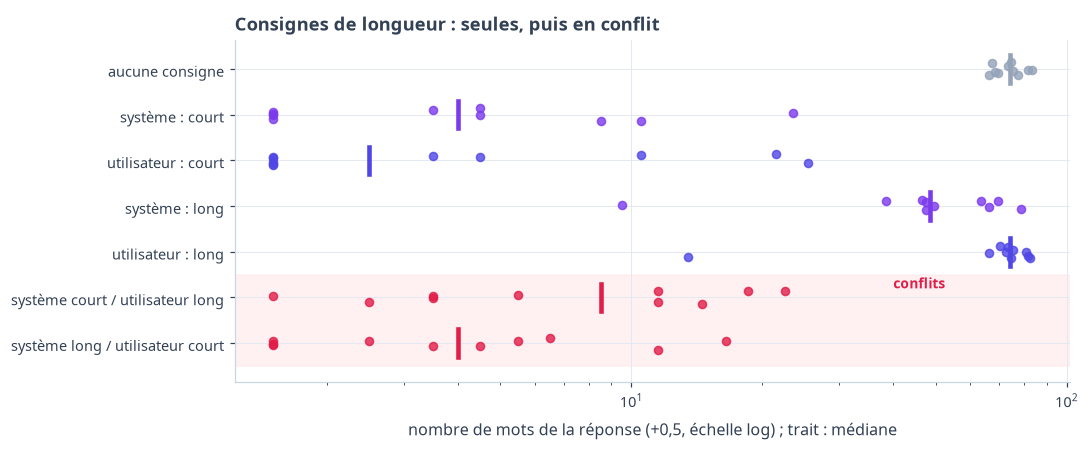

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.2))
noms = list(CAS)
couleurs = [GRAY, VIOLET, INDIGO, VIOLET, INDIGO, ROSE, ROSE]
for i, (nom, c) in enumerate(zip(noms, couleurs)):
    v = conflit[conflit.cas == nom].mots.values
    ax.scatter(v + 0.5, i + np.random.default_rng(i).uniform(-0.15, 0.15, len(v)), color=c, s=28, alpha=0.8, zorder=3)
    ax.plot([np.median(v) + 0.5] * 2, [i - 0.3, i + 0.3], color=c, lw=3)
ax.set_xscale("log")
ax.set_yticks(range(len(noms)), noms)
ax.invert_yaxis()
ax.axhspan(4.5, 6.5, color=LIGHT[ROSE], alpha=0.5, zorder=0)
ax.text(40, 4.8, "conflits", color=ROSE, fontsize=9, fontweight="bold")
ax.set_xlabel("nombre de mots de la réponse (+0,5, échelle log) ; trait : médiane")
ax.set_title("Consignes de longueur : seules, puis en conflit")
finish(fig)
plt.show()

**Lecture.** Chaque consigne, donnée seule, est plutôt bien suivie, qu'elle vienne du système
ou de l'utilisateur. En cas de conflit, il n'y a pas de hiérarchie claire **par rôle** : la
consigne « en un seul mot » tend à l'emporter d'où qu'elle vienne. Le petit Qwen ne respecte
donc pas une priorité stricte du système sur l'utilisateur. (Autre observation : une consigne
de langue comme « Always answer in English » placée dans le système est largement ignorée
quand la question est en français ; la robustesse au suivi d'instructions dépend fortement du
type de consigne, comme l'a montré le chapitre 4.)

C'est exactement la faiblesse qu'exploitent les attaques par injection (cours 4) et que la
**hiérarchie d'instructions** de Wallace et al. (2024) cherche à corriger par
post-entraînement : les instructions du système doivent primer sur celles de l'utilisateur,
qui priment sur celles des outils.

> **À retenir.** Le prompt système n'a pas de « super-pouvoir » architectural : il est
> premier dans la séquence, et le modèle a peut-être appris à le privilégier. Sur un petit
> modèle, cette priorité est faible : il faut la mesurer.

## 5. Longueur de contexte et coût du contexte (section *Context Length and Context Efficiency*)

**Motivation.** Ce que l'on peut mettre dans un prompt est borné par la **longueur de
contexte** maximale. Elle a explosé : de 1K tokens (GPT-2, 2019) à 2M (Gemini 1.5 Pro, 2024),
soit un facteur 2 000 en cinq ans. Pour fixer les idées, le livre estime qu'un livre de 120 000
mots fait environ 160 000 tokens.

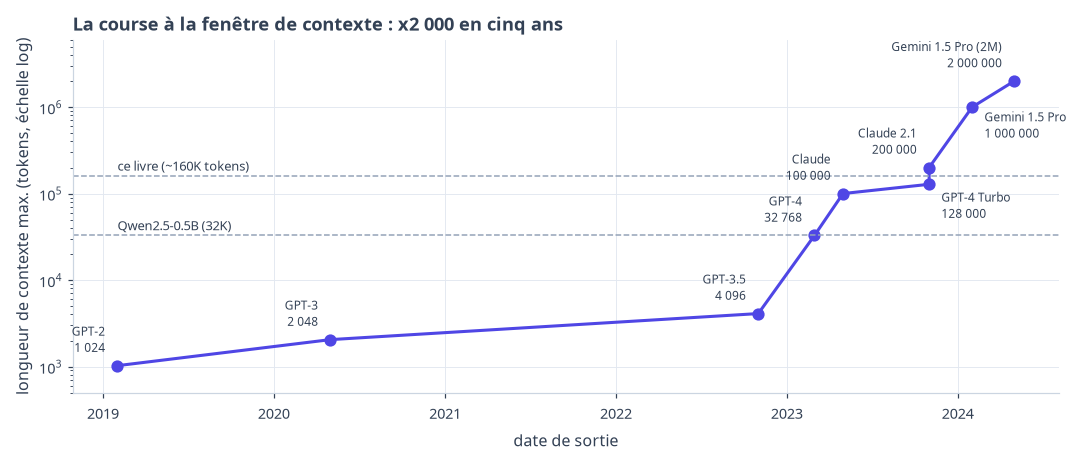

In [14]:
cl = pd.DataFrame(P.CONTEXT_LENGTHS, columns=["modele", "date", "tokens"])
cl["date"] = pd.to_datetime(cl.date)
fig, ax = plt.subplots(figsize=(10, 4.3))
ax.semilogy(cl.date, cl.tokens, "o-", color=INDIGO, ms=7)
decalages = {"GPT-4 Turbo": (8, -22, "left"), "Gemini 1.5 Pro": (8, -20, "left")}
for _, r in cl.iterrows():
    dx, dy, ha = decalages.get(r.modele, (-8, 9, "right"))
    ax.annotate(f"{r.modele}\n{r.tokens:,}".replace(",", " "), (r.date, r.tokens), textcoords="offset points",
                xytext=(dx, dy), fontsize=7.8, ha=ha)
for y, lab in [(160_000, "ce livre (~160K tokens)"), (32_768, "Qwen2.5-0.5B (32K)")]:
    ax.axhline(y, color=GRAY, ls="--", lw=1)
    ax.text(cl.date.iloc[0], y * 1.15, lab, fontsize=8.5, color=SLATE)
ax.set_ylabel("longueur de contexte max. (tokens, échelle log)")
ax.set_xlabel("date de sortie")
ax.set_ylim(500, 6e6)
ax.set_title("La course à la fenêtre de contexte : x2 000 en cinq ans")
finish(fig)
plt.show()

**Ce que coûte un long contexte.** Deux postes, à calculer soi-même :

1. **la mémoire du cache clés-valeurs (KV)** : pendant la génération, chaque couche garde les
   clés et valeurs de tous les tokens passés :
   $$M_\text{KV} = 2 \times L \times h_\text{KV} \times d_\text{tête} \times n \times b,$$
   avec $L$ couches, $h_\text{KV}$ têtes clé-valeur, $d_\text{tête}$ la dimension d'une tête,
   $n$ tokens et $b$ octets par valeur (2 en bf16). C'est **linéaire** en $n$.
2. **le calcul de l'attention** au préremplissage : les produits $QK^\top$ et $AV$ coûtent
   environ $4\,L\,d\,n^2$ FLOPs, soit une croissance **quadratique** en $n$ (les couches MLP
   restent, elles, linéaires en $n$).

Appliquons ces formules à Qwen2.5-0.5B, dont on lit la configuration.

In [15]:
cfg = AutoConfig.from_pretrained(llm.SMALL)
L, h_kv, d_model, n_heads = cfg.num_hidden_layers, cfg.num_key_value_heads, cfg.hidden_size, cfg.num_attention_heads
d_head = d_model // n_heads
print(f"couches = {L}, têtes de requête = {n_heads}, têtes KV = {h_kv} (attention groupée), "
      f"d_tête = {d_head}, contexte max = {cfg.max_position_embeddings}")
par_token = P.kv_cache_bytes(1, L, h_kv, d_head)
sans_gqa = P.kv_cache_bytes(1, L, n_heads, d_head)
print(f"cache KV : {par_token / 1024:.0f} Kio par token (il en faudrait {sans_gqa / 1024:.0f} sans GQA)")
for n in [4_096, 32_768]:
    print(f"  {n:>6} tokens -> {P.kv_cache_bytes(n, L, h_kv, d_head) / 2**20:.0f} Mio par séquence")

couches = 24, têtes de requête = 14, têtes KV = 2 (attention groupée), d_tête = 64, contexte max = 32768
cache KV : 12 Kio par token (il en faudrait 84 sans GQA)
    4096 tokens -> 48 Mio par séquence
   32768 tokens -> 384 Mio par séquence


Grâce à l'**attention groupée** (GQA : 2 têtes KV partagées par 14 têtes de requête), le cache
de Qwen2.5-0.5B ne pèse que 12 Kio par token : 384 Mio pour 32K tokens. Sans GQA, ce serait
7 fois plus. Vérifions maintenant expérimentalement le coût du préremplissage.

In [16]:
tk, model = llm.load(llm.SMALL)
longueurs = [512, 1024, 2048, 4096, 8192, 16384]
mesures = []
for n in longueurs:
    ids = torch.randint(1000, 20000, (1, n), device=model.device)
    with torch.no_grad():
        model(ids, logits_to_keep=1)  # échauffement (on ne calcule que les derniers logits)
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(3):
            model(ids, logits_to_keep=1)
        torch.cuda.synchronize()
    mesures.append(dict(n=n, secondes=(time.perf_counter() - t0) / 3))
lat = pd.DataFrame(mesures)
lat["ms_par_token"] = 1000 * lat.secondes / lat.n
lat["part_attention_theorique"] = [P.attention_flops(n, L, d_model) /
                                   (P.attention_flops(n, L, d_model) + 2 * 0.36e9 * n) for n in lat.n]
lat.round(4)

,n,secondes,ms_par_token,part_attention_theorique
0,512,0.0146,0.0284,0.0576
1,1024,0.0268,0.0262,0.1090
2,2048,0.0535,0.0261,0.1966
3,4096,0.1151,0.0281,0.3286
4,8192,0.2811,0.0343,0.4946
5,16384,0.7140,0.0436,0.6619


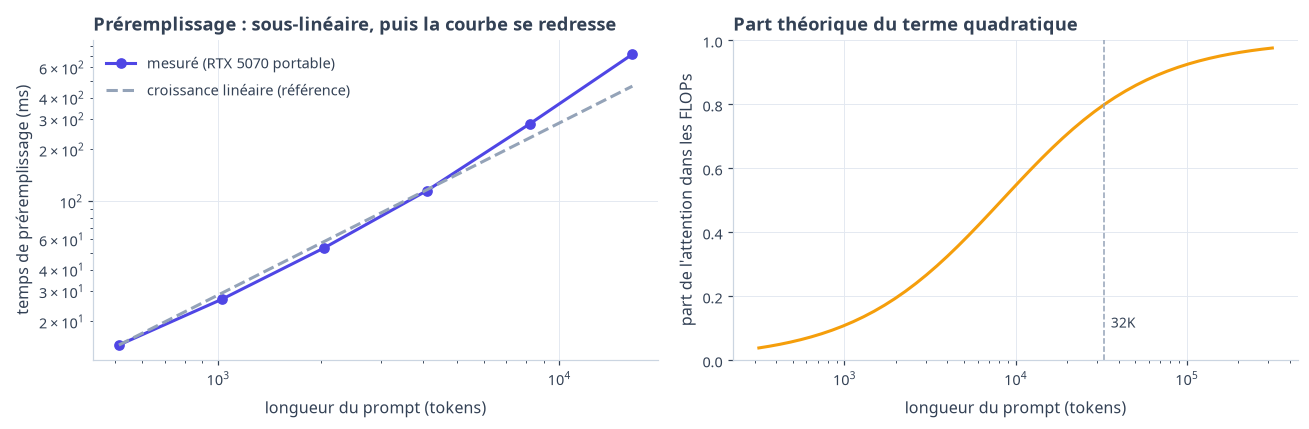

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.loglog(lat.n, lat.secondes * 1000, "o-", color=INDIGO, label="mesuré (RTX 5070 portable)")
ref = lat.secondes.iloc[0] * 1000 * lat.n / lat.n.iloc[0]
ax.loglog(lat.n, ref, "--", color=GRAY, label="croissance linéaire (référence)")
ax.set_xlabel("longueur du prompt (tokens)")
ax.set_ylabel("temps de préremplissage (ms)")
ax.set_title("Préremplissage : sous-linéaire, puis la courbe se redresse")
ax.legend()
ax = axes[1]
nn = np.logspace(2.5, 5.5, 50)
part = [P.attention_flops(n, L, d_model) / (P.attention_flops(n, L, d_model) + 2 * 0.36e9 * n) for n in nn]
ax.semilogx(nn, part, color=AMBER)
ax.axvline(cfg.max_position_embeddings, color=GRAY, ls="--", lw=1)
ax.text(cfg.max_position_embeddings * 1.1, 0.1, "32K", fontsize=9)
ax.set_xlabel("longueur du prompt (tokens)")
ax.set_ylabel("part de l'attention dans les FLOPs")
ax.set_ylim(0, 1)
ax.set_title("Part théorique du terme quadratique")
finish(fig)
plt.show()

**Lecture.** Le modèle théorique (figure de droite) compte environ $2N$ FLOPs par token pour
les produits matriciels des couches ($N \approx 0{,}36$ milliard de paramètres hors
embeddings) plus $4\,L\,d\,n^2$ pour l'attention : au-delà de quelques milliers de tokens,
l'attention devient le poste dominant. La mesure (à gauche) le confirme à sa façon : sur les
prompts courts, le temps croît **moins** vite que linéairement (le GPU est sous-utilisé, un
lot plus long l'occupe mieux), puis la courbe se redresse nettement entre 8K et 16K tokens,
là où le terme quadratique se fait sentir. Un long contexte coûte donc en **mémoire** (cache KV), en **latence** (temps avant
le premier token) et en **argent** (tokens facturés). Le chapitre 9 reviendra sur
l'optimisation de l'inférence.

> **À retenir.** Le cache KV croît linéairement avec le contexte, le calcul de l'attention
> quadratiquement. Une grande fenêtre n'est pas gratuite : on ne la remplit que si
> l'information est utile.

## 6. L'aiguille dans une botte de foin (section *Context Length and Context Efficiency*)

**Motivation.** Pouvoir *mettre* 32K tokens dans un prompt ne veut pas dire que le modèle les
*exploite* tous aussi bien. Liu et al. (2023, « Lost in the Middle ») ont montré que les
modèles retrouvent mieux une information placée **au début ou à la fin** du prompt qu'au
milieu. Le test de l'**aiguille dans une botte de foin** (*needle in a haystack*, NIAH)
consiste à insérer une information (l'aiguille) à différentes profondeurs d'un long texte et
à demander au modèle de la retrouver.

Le livre conseille d'utiliser une information **privée** (que le modèle ne peut pas connaître
par son pré-entraînement) : nos aiguilles sont des faits inventés.

**Version 1 : aiguille facile.** Une phrase unique au milieu de phrases de remplissage sans
rapport. La question reprend les mots de l'aiguille.

In [18]:
hay = P.make_haystack(6, P.NEEDLES[0][0], depth=0.5)
print(P.niah_prompt(hay, P.NEEDLES[0][1])[:600], "...")
rows = []
for n in [20, 150, 600]:
    for depth in [0, 0.5, 1]:
        for i in range(len(P.NEEDLES)):
            rows.append(P.niah_trial(n, depth, needle_idx=i, seed=i))
facile = pd.DataFrame(rows)
facile["taille"] = facile.n_tokens.round(-2)
print(facile.groupby([pd.cut(facile.n_tokens, [0, 1000, 5000, 20000], labels=["~0,5K", "~3K", "~13K"]), "depth"],
                     observed=True).ok.mean().unstack())

Lis le document suivant puis réponds à la question.

Document :
La chorale a précisé le report de la brocante à la demande des habitants. Le marché couvert a annoncé un nouveau calendrier d'ouverture pour le mois prochain. La bibliothèque municipale a publié une conférence sur l'histoire locale lors de la dernière réunion. Le code du cadenas de la remise de Mme Ferrand est 4827. Le conseil de quartier a précisé la fermeture estivale avec le soutien de la région. La médiathèque a précisé le report de la brocante lors de la dernière réunion. Le marché couvert a publié un concours de dessin pour  ...


depth     0.0  0.5  1.0
n_tokens               
~0,5K     1.0  1.0  1.0
~3K       1.0  1.0  1.0
~13K      1.0  1.0  1.0


Le petit modèle retrouve presque toujours l'aiguille facile, même dans plus de 10 000 tokens :
la question partage des mots rares avec l'aiguille (« cadenas », « Ferrand »), l'attention
n'a qu'à les « repérer ». Ce test est trop facile pour être informatif.

**Version 2 : aiguille parmi des leurres.** Inspirée de la tâche clé-valeur de Liu et al., la
botte de foin est faite de phrases **toutes de même forme** (« Le code du casier de Prénom Nom
est NNNN. ») : il faut retrouver la bonne paire parmi des dizaines de leurres.

In [19]:
txt, q, rep = P.make_kv_haystack(5, depth=0.5, seed=0)
print(txt, "\n->", q, "| réponse attendue :", rep)

Le code du casier de Antoine Fournier est 9415. Le code du casier de Farid Dupont est 7562. Le code du casier de Paul Leroy est 5891. Le code du casier de Jules Bernard est 6038. Le code du casier de Chloé Martin est 6688. 
-> Quel est le code du casier de Paul Leroy ? | réponse attendue : 5891


In [20]:
TAILLES = [10, 40, 80, 160, 320]
PROFONDEURS = [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0]
N_SEEDS = 8
t0 = time.time()
essais = pd.DataFrame([dict(n_paires=n, **P.kv_trial(n, d, seed=s))
                       for n in TAILLES for d in PROFONDEURS for s in range(N_SEEDS)])
print(f"{len(essais)} essais en {time.time() - t0:.0f} s")
grille = essais.pivot_table(index="n_paires", columns="depth", values="ok", aggfunc="mean")
tokens_moy = essais.groupby("n_paires").n_tokens.mean().round(-1).astype(int)
grille.round(2)

280 essais en 32 s


depth,0.00,0.10,0.25,0.50,0.75,0.90,1.00
n_paires,,,,,,,
10,1.0,1.00,1.00,0.88,0.62,0.88,0.75
40,1.0,0.88,0.50,0.50,0.38,0.50,0.75
80,1.0,0.50,0.50,0.12,0.50,0.50,0.38
160,1.0,0.50,0.12,0.25,0.25,0.50,0.62
320,1.0,0.50,0.50,0.25,0.62,0.50,0.88


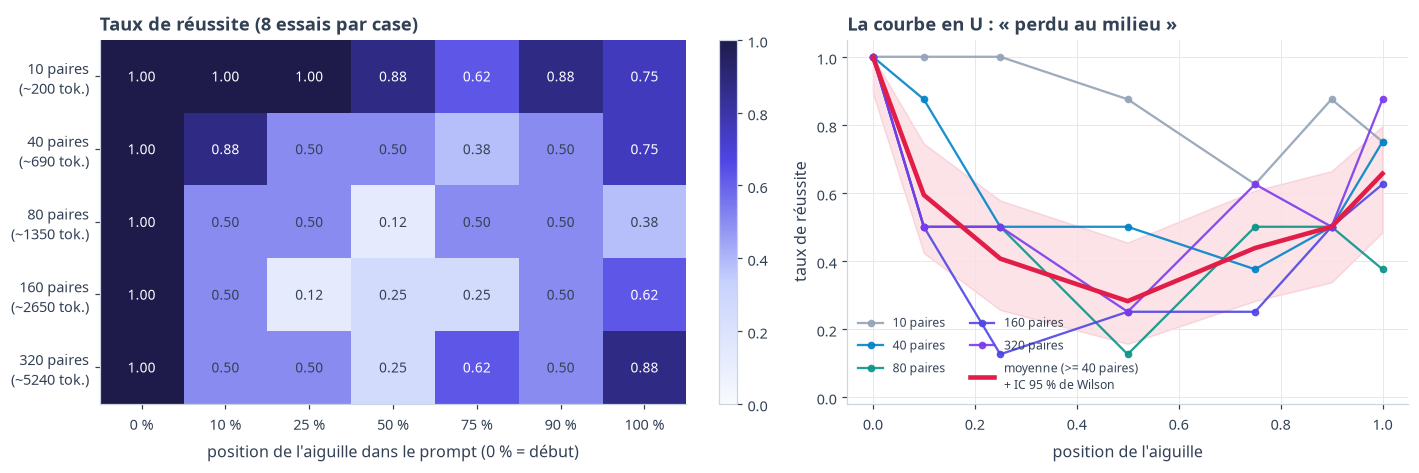

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
im = ax.imshow(grille.values, cmap="aie_seq", vmin=0, vmax=1, aspect="auto")
for i in range(grille.shape[0]):
    for j in range(grille.shape[1]):
        v = grille.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if v > 0.6 else SLATE)
ax.set_xticks(range(len(PROFONDEURS)), [f"{int(p * 100)} %" for p in PROFONDEURS])
ax.set_yticks(range(len(TAILLES)), [f"{n} paires\n(~{tokens_moy[n]} tok.)" for n in TAILLES])
ax.set_xlabel("position de l'aiguille dans le prompt (0 % = début)")
ax.set_title("Taux de réussite (8 essais par case)")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04)
ax = axes[1]
for n, c in zip(TAILLES, [GRAY, SKY, TEAL, INDIGO, VIOLET]):
    ax.plot(PROFONDEURS, grille.loc[n], "o-", color=c, ms=4, lw=1.5, label=f"{n} paires", alpha=0.9)
moy = essais[essais.n_paires >= 40].groupby("depth").ok.agg(["sum", "count"])
lo_hi = np.array([P.wilson_interval(int(s), int(c)) for s, c in zip(moy["sum"], moy["count"])])
ax.fill_between(PROFONDEURS, lo_hi[:, 0], lo_hi[:, 1], color=ROSE, alpha=0.12)
ax.plot(PROFONDEURS, moy["sum"] / moy["count"], color=ROSE, lw=3, label="moyenne (>= 40 paires)\n+ IC 95 % de Wilson")
ax.set_xlabel("position de l'aiguille")
ax.set_ylabel("taux de réussite")
ax.set_ylim(-0.02, 1.05)
ax.set_title("La courbe en U : « perdu au milieu »")
ax.legend(fontsize=8, loc="lower left", ncol=2)
finish(fig)
plt.show()

**Lecture.** On retrouve, à petite échelle, le phénomène de Liu et al. :

- une information placée **tout au début** du prompt est retrouvée presque à coup sûr
  (biais de primauté) ; la **fin** est aussi relativement favorable (biais de récence) ;
- le **milieu** est la zone la plus mal exploitée, et l'effet s'aggrave quand la botte de foin
  s'allonge : la difficulté vient autant de la *position* que de la *quantité de leurres* ;
- l'intervalle de Wilson rappelle qu'avec quelques dizaines d'essais par position, seuls les
  écarts importants sont significatifs (l'exercice 5.6 fait le test statistique).

**Conséquences pratiques** : placer les instructions et les informations critiques au début
ou à la fin ; ne pas noyer le modèle sous des documents peu pertinents (c'est tout l'enjeu de
la recherche d'information du chapitre 6) ; et tester son propre modèle avec ses propres
données (le livre cite RULER, Hsieh et al. 2024, comme banc d'essai plus complet).

> **À retenir.** La longueur de contexte annoncée est une capacité, pas une garantie
> d'utilisation. Le test de l'aiguille, surtout avec des leurres, révèle une courbe en U :
> le milieu d'un long prompt est la zone la moins fiable.

## Synthèse

- Prompt système et prompt utilisateur sont **concaténés** en une séquence par le **gabarit de
  conversation** ; les tokens spéciaux (`<|im_start|>`, `<|im_end|>`) sont atomiques, et le
  gabarit de Qwen insère un prompt système par défaut.
- Une **erreur de gabarit** ne plante pas : elle dégrade la précision en silence. On utilise
  `apply_chat_template` et on imprime le prompt final.
- La **priorité du prompt système** n'est qu'apprise : sur un petit modèle, une consigne
  utilisateur contraire l'emporte souvent. Prélude aux attaques du cours 4.
- Un long contexte coûte en mémoire (cache KV linéaire) et en calcul (attention quadratique).
- Le test de l'**aiguille dans une botte de foin** avec leurres fait apparaître une courbe en
  U : début et fin sont mieux exploités que le milieu.
- Liens : architecture et attention au chapitre 2, latence et coût d'inférence au chapitre 9,
  construction du contexte (RAG) au chapitre 6.

In [22]:
llm.free_gpu()